<a href="https://colab.research.google.com/github/PrinzVike/csc4110_G02/blob/main/G02_U2_2_eda_split.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 4110 – Group G2
## Task 2.2: Transformation, EDA and Split
**Task owner:** Prince Emmanuel  
**Registration number:** COM/0072/23  
**Module:** 3

This notebook transforms the cleaned insurance dataset, explores its features, scales `age`, and creates a leakage-safe regression train/test split.

**Input required:** `data/stage1_insurance.csv` produced by Member 1 in Task 2.1.  
**Output required:** `data/clean_insurance.csv`, five charts in `outputs/`, and the variables specified in the assignment.

In [ ]:
# Import the libraries and configure reproducible results and output folders.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

RANDOM_STATE = 42
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
sns.set_theme(style="whitegrid")

In [ ]:
import os

# Check if the 'data' directory exists and list its contents
if os.path.exists('data'):
    print("✅ 'data/' folder exists.")
    files = os.listdir('data')
    print(f"Files in 'data/': {files}")

    # Check if the specific CSV file is inside the directory
    if 'stage1_insurance.csv' in files:
        print("🎉 'stage1_insurance.csv' is correctly placed in the 'data/' folder!")
    else:
        print("❌ 'stage1_insurance.csv' is missing from 'data/'. Please upload or copy it there.")
else:
    print("❌ 'data/' folder does not exist at all.")

✅ 'data/' folder exists.
Files in 'data/': []
❌ 'stage1_insurance.csv' is missing from 'data/'. Please upload or copy it there.


In [ ]:
# Load the cleaned dataset created in Task 2.1 and inspect its dimensions.
input_path = "data/stage1_insurance.csv"
if not os.path.exists(input_path):
    raise FileNotFoundError(
        "Missing data/stage1_insurance.csv. Obtain it from Member 1's Task 2.1 "
        "and place it in the project's data folder."
    )

df = pd.read_csv(input_path)
print("Shape:", df.shape)
display(df.head())
print("\nColumns:", df.columns.tolist())

Shape: (1337, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Columns: ['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


## A. Transform the data

The categorical variables `sex` and `smoker` are mapped to binary values. `region` is one-hot encoded because its four categories have no natural numerical order. Coding regions as 0, 1, 2 and 3 would incorrectly imply that one region is quantitatively greater than another.

In [ ]:
# Encode binary categories and one-hot encode the nominal region category.
df_clean = df.copy()

df_clean["sex"] = df_clean["sex"].map({"female": 0, "male": 1})
df_clean["smoker"] = df_clean["smoker"].map({"no": 0, "yes": 1})

if df_clean[["sex", "smoker"]].isna().any().any():
    raise ValueError("Unexpected sex or smoker category. Check the source values.")

df_clean = pd.get_dummies(
    df_clean,
    columns=["region"],
    prefix="region",
    dtype=int
)

# Create the log-transformed target and the BMI-by-smoker interaction for EDA.
df_clean["log_charges"] = np.log(df_clean["charges"])
df_clean["bmi_smoker"] = df_clean["bmi"] * df_clean["smoker"]

# Create BMI bands for grouped exploratory analysis.
df_clean["bmi_band"] = pd.cut(
    df_clean["bmi"],
    bins=[-np.inf, 18.5, 25, 30, np.inf],
    labels=["under 18.5", "18.5–25", "25–30", "30 and over"],
    right=False
)

display(df_clean.head())
print("Transformed shape:", df_clean.shape)

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,log_charges,bmi_smoker,bmi_band
0,19,0,27.900,0,1,16884.92400,0,0,0,1,9.734176,27.9,25–30
1,18,1,33.770,1,0,1725.55230,0,0,1,0,7.453302,0.0,30 and over
2,28,1,33.000,3,0,4449.46200,0,0,1,0,8.400538,0.0,30 and over
3,33,1,22.705,0,0,21984.47061,0,1,0,0,9.998092,0.0,18.5–25
4,32,1,28.880,0,0,3866.85520,0,1,0,0,8.260197,0.0,25–30


Transformed shape: (1337, 13)


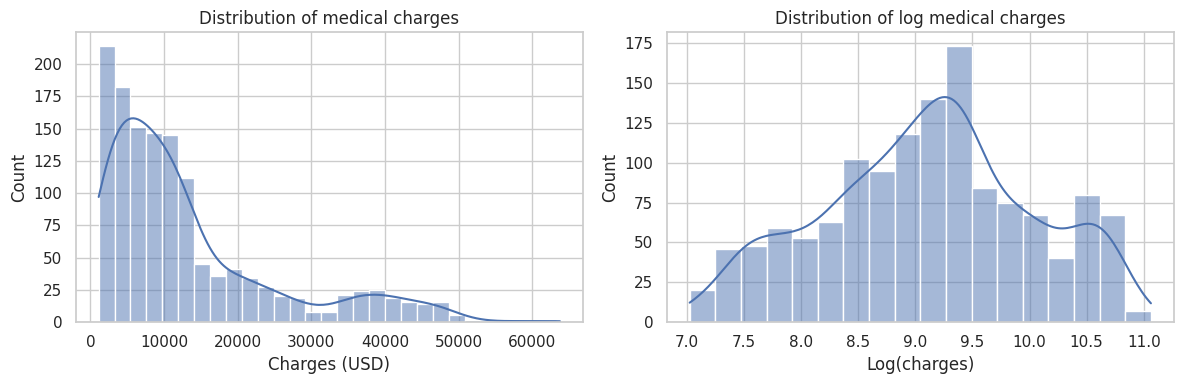

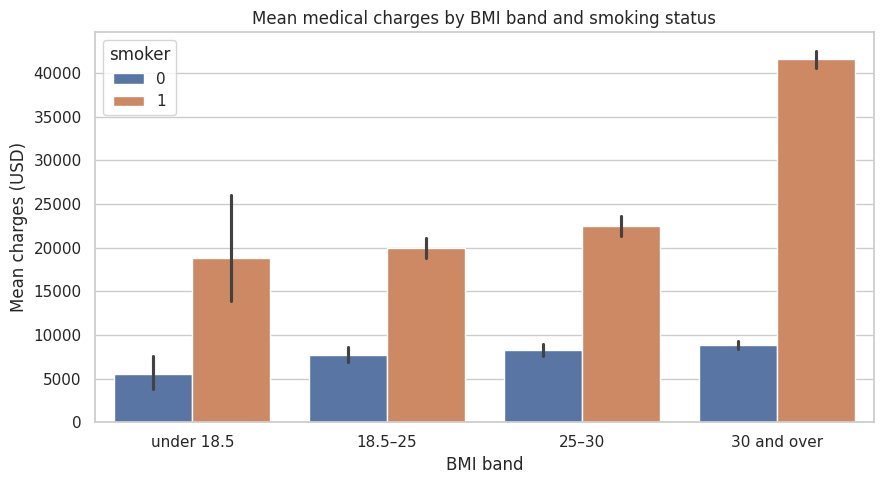

In [ ]:
# Compare the original charges distribution with its logarithmic transformation.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_clean["charges"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of medical charges")
axes[0].set_xlabel("Charges (USD)")
sns.histplot(df_clean["log_charges"], kde=True, ax=axes[1])
axes[1].set_title("Distribution of log medical charges")
axes[1].set_xlabel("Log(charges)")
plt.tight_layout()
plt.show()

# Compare mean charges across BMI bands for smokers and non-smokers.
plt.figure(figsize=(9, 5))
sns.barplot(data=df_clean, x="bmi_band", y="charges", hue="smoker")
plt.title("Mean medical charges by BMI band and smoking status")
plt.xlabel("BMI band")
plt.ylabel("Mean charges (USD)")
plt.tight_layout()
plt.show()

In [ ]:
# Save the transformed dataset using the exact filename required by the assignment.
clean_path = "data/clean_insurance.csv"
df_clean.to_csv(clean_path, index=False)
print(f"Saved {clean_path}")

Saved data/clean_insurance.csv


## B. Explore the data visually

The five labelled charts below are saved using the exact filenames required by the assessment. The best numeric predictor is selected using absolute correlation with `charges` among numeric columns, excluding the target and engineered leakage/interaction columns.

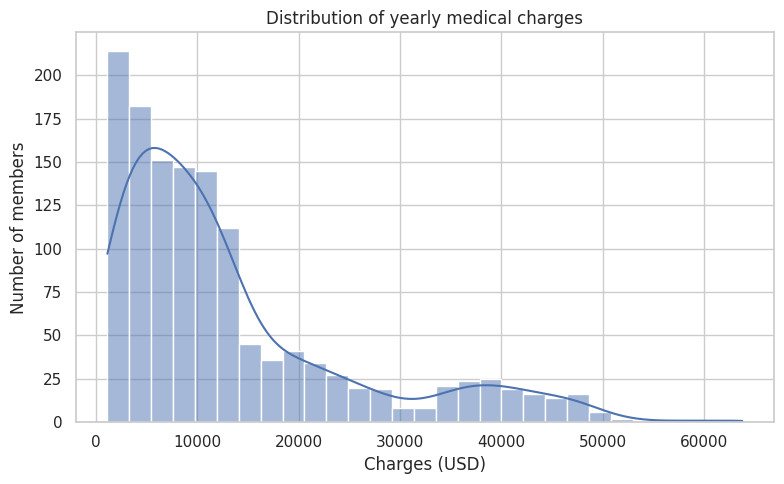

In [ ]:
# Plot and save the distribution of the regression target.
plt.figure(figsize=(8, 5))
sns.histplot(df_clean["charges"], kde=True)
plt.title("Distribution of yearly medical charges")
plt.xlabel("Charges (USD)")
plt.ylabel("Number of members")
plt.tight_layout()
plt.savefig("outputs/hist_target.png", dpi=300)
plt.show()

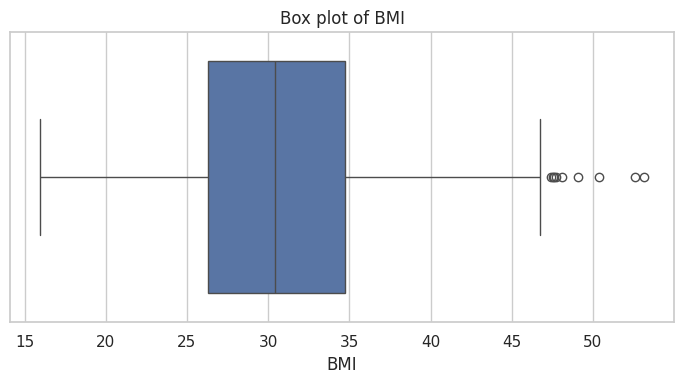

In [ ]:
# Plot and save a box plot of BMI as a numeric feature.
plt.figure(figsize=(7, 4))
sns.boxplot(x=df_clean["bmi"])
plt.title("Box plot of BMI")
plt.xlabel("BMI")
plt.tight_layout()
plt.savefig("outputs/box_feature.png", dpi=300)
plt.show()

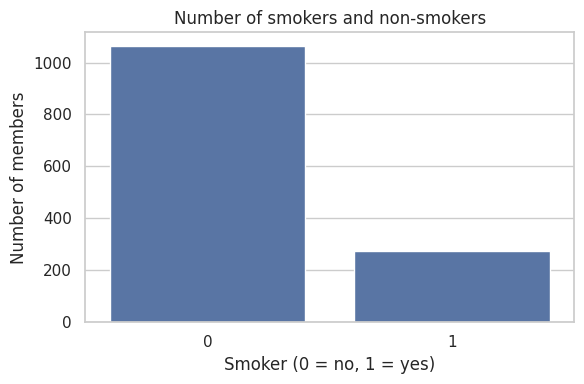

In [ ]:
# Plot and save the smoker class counts.
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x="smoker")
plt.title("Number of smokers and non-smokers")
plt.xlabel("Smoker (0 = no, 1 = yes)")
plt.ylabel("Number of members")
plt.tight_layout()
plt.savefig("outputs/bar_class.png", dpi=300)
plt.show()

Best numeric predictor by absolute correlation: smoker
Correlation with charges: 0.7872343672800317


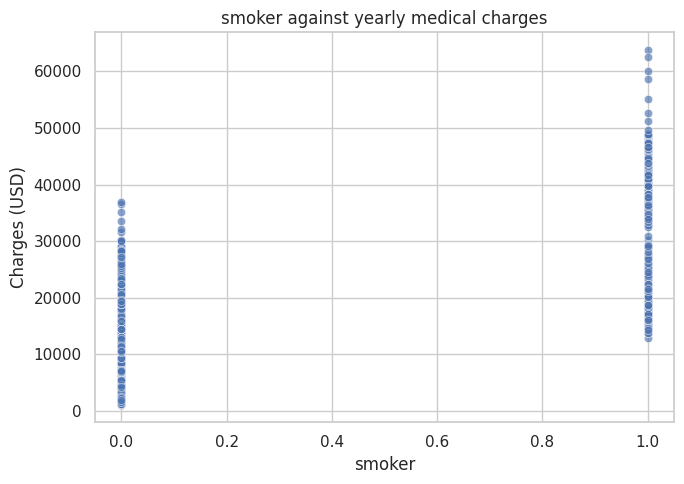

In [ ]:
# Find the strongest numeric predictor of charges and plot it against the target.
numeric_corr = df_clean.select_dtypes(include=np.number).corr()["charges"].drop(
    labels=["charges", "log_charges", "bmi_smoker"], errors="ignore"
)
best_numeric_predictor = numeric_corr.abs().idxmax()
print("Best numeric predictor by absolute correlation:", best_numeric_predictor)
print("Correlation with charges:", numeric_corr[best_numeric_predictor])

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_clean, x=best_numeric_predictor, y="charges", alpha=0.65)
plt.title(f"{best_numeric_predictor} against yearly medical charges")
plt.xlabel(best_numeric_predictor)
plt.ylabel("Charges (USD)")
plt.tight_layout()
plt.savefig("outputs/scatter_best.png", dpi=300)
plt.show()

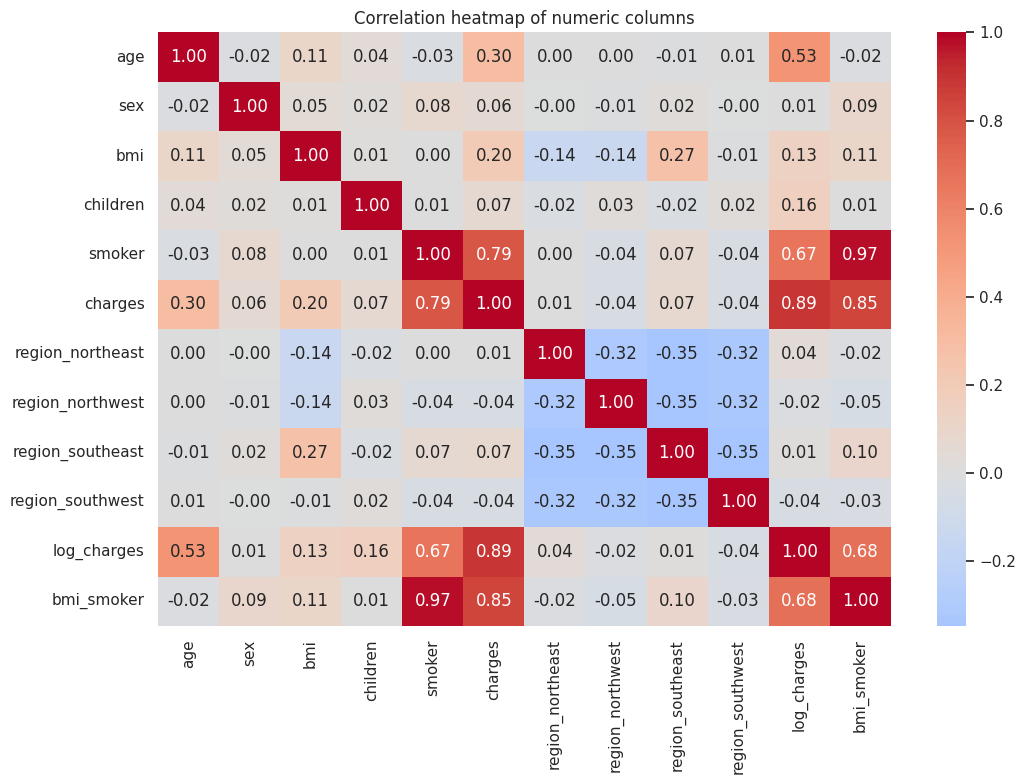

In [ ]:
# Plot and save a correlation heatmap for the numeric columns.
numeric_df = df_clean.select_dtypes(include=np.number)
plt.figure(figsize=(11, 8))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap of numeric columns")
plt.tight_layout()
plt.savefig("outputs/corr_heatmap.png", dpi=300)
plt.show()

## C. Exam skill: Min–max scaling and standard scaling

Min–max scaling maps values to a fixed range, normally 0 to 1. Standard scaling transforms values to have a mean of approximately 0 and a standard deviation of approximately 1. Both scalers below are demonstrated on `age`; the demonstrations are fitted on the complete age column only for this isolated exercise. For model training, preprocessing must instead be fitted on training data only.

In [ ]:
# Demonstrate both scaling methods on age and display the first five values side by side.
age_values = df_clean[["age"]].astype(float)

minmax_demo = MinMaxScaler()
standard_demo = StandardScaler()

age_minmax = minmax_demo.fit_transform(age_values).ravel()
age_standard = standard_demo.fit_transform(age_values).ravel()

scaling_comparison = pd.DataFrame({
    "original_age": age_values["age"].head(5).values,
    "minmax_age": age_minmax[:5],
    "standard_age": age_standard[:5]
})
display(scaling_comparison)

,original_age,minmax_age,standard_age
0,19.0,0.021739,-1.440418
1,18.0,0.000000,-1.511647
2,28.0,0.217391,-0.799350
3,33.0,0.326087,-0.443201
4,32.0,0.304348,-0.514431


**When to use each scaler:** Min–max scaling is useful when an algorithm expects or benefits from a bounded feature range, such as some neural networks and distance-based methods. Standard scaling is useful for algorithms sensitive to feature magnitude, including logistic regression, support vector machines and multilayer perceptrons. Standard scaling does not bound values and can still be affected by outliers.

## D. Split the data without leakage

The regression target is `charges`. The feature matrix excludes both `charges` and `log_charges`; the latter is a transformation of the target and would leak the answer into the model. The scaler is fitted only on `X_train` and then applied to `X_test`, preventing information from the test set from influencing preprocessing.

In [ ]:
# Separate regression features and target, excluding both target columns and EDA-only BMI band.
target_columns = ["charges", "log_charges"]
excluded_columns = target_columns + ["bmi_band"]
X = df_clean.drop(columns=excluded_columns, errors="ignore").copy()
y = df_clean["charges"].copy()

# Ensure all model features are numeric after the categorical transformations.
X = X.apply(pd.to_numeric, errors="raise")

# Split the records into 80% training and 20% testing using the required seed.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# Fit the standard scaler on training data only, then transform both partitions.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("Scaler fitted on training data only.")
assert "log_charges" not in X_train.columns

X_train: (1069, 10)
X_test: (268, 10)
y_train: (1069,)
y_test: (268,)
Scaler fitted on training data only.


In [ ]:
# Summarise key exploratory findings numerically for the written assessment response.
smoker_counts = df_clean["smoker"].value_counts().sort_index()
smoker_pct = df_clean["smoker"].value_counts(normalize=True).sort_index() * 100
print(f"1) Charges are right-skewed: skewness = {df_clean['charges'].skew():.2f}.")
print(f"2) The strongest numeric predictor by absolute correlation is "
      f"{best_numeric_predictor} (r = {numeric_corr[best_numeric_predictor]:.3f}).")
print(f"3) Non-smokers: {smoker_counts.get(0, 0)} ({smoker_pct.get(0, 0):.1f}%). "
      f"Smokers: {smoker_counts.get(1, 0)} ({smoker_pct.get(1, 0):.1f}%).")
print("The scaler is fitted only on training data to prevent test-set information "
      "from influencing the transformation and causing data leakage.")

1) Charges are right-skewed: skewness = 1.52.
2) The strongest numeric predictor by absolute correlation is smoker (r = 0.787).
3) Non-smokers: 1063 (79.5%). Smokers: 274 (20.5%).
The scaler is fitted only on training data to prevent test-set information from influencing the transformation and causing data leakage.


## Written answer

After running all cells, use the printed numerical results above to complete this answer in your own words:

1. The charges distribution is strongly right-skewed (report the measured skewness); the log transformation makes the distribution more suitable for analysis by reducing the influence of the long right tail.
2. The strongest numeric predictor by absolute correlation is the feature printed above (report its correlation coefficient).
3. The smoker class counts and percentages are printed above; this shows the class imbalance in the dataset.
4. The scatter plot and correlation heatmap help show how numeric features relate to yearly charges, while the BMI-band chart compares mean charges by smoking status.
5. The scaler must be fitted on training data only because fitting it on the complete dataset would allow information from the test set to influence the transformation, causing data leakage.

**Before submission:** verify that all five files exist in `outputs/` and `data/clean_insurance.csv` exists.